<a href="https://colab.research.google.com/github/Jackson-Coulson/mis433/blob/main/Coulson_Jackson_assignment_IMDB_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment - Analyzing the IMDB Top 1000 Movies

In this assignment, you will be working with this dataset of IMDB top 1000 movies.

Source: https://www.kaggle.com/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows

In [1]:
import pandas as pd
import numpy as np

In [2]:
# Read the data file "imdb_top_1000.csv" to a dataframe named "imdb"
imdb = pd.read_csv('https://raw.githubusercontent.com/jiexunli-wwu/mis433/refs/heads/main/data/imdb_top_1000.csv', header=0)
imdb.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [3]:
# Describe the dataframe using the info() method.
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   object 
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    object 
dtypes: float64(2), int64(1), object(13)
memory usage: 125.1+ KB


In [4]:
# List all the column names:
imdb.columns

Index(['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate',
       'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross'],
      dtype='object')

## Part 1: Data Manipulation

Redo the following to clean the data.

In [9]:
# Count the number of movies in each "Released_Year".
# Hint: value_counts()
imdb['Released_Year'].value_counts()

,count
Released_Year,
2014,32
2004,31
2009,29
2013,28
2016,28
...,...
1920,1
1930,1
1922,1


In [15]:
# In this dataset, there is a movie with an error in "Released_Year".
# Hint: Released_Year should be a 4-digit integer but this movie's year is not.
# Find this movie.
imdb[imdb['Released_Year'] == 'PG']

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross


In [14]:
# Correct the values for the corresponding columns ("Released_Year" and "Certificate").
# You may want to look up this movie on www.imdb.com.
# Hint: You can set value for a particular row by: df.loc[row_index, column_name] = new_value

imdb.loc[imdb['Series_Title'] == 'Apollo 13', 'Released_Year'] = '1995'
imdb.loc[imdb['Series_Title'] == 'Apollo 13', 'Certificate'] = 'PG'


In [17]:
imdb[imdb['Series_Title'] == 'Apollo 13']

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
966,https://m.media-amazon.com/images/M/MV5BNjEzYj...,Apollo 13,1995,PG,140 min,"Adventure, Drama, History",7.6,NASA must devise a strategy to return Apollo 1...,77.0,Ron Howard,Tom Hanks,Bill Paxton,Kevin Bacon,Gary Sinise,269197,"173,837,933"


In [18]:
# Change the data type of "Released_Year" to int

imdb['Released_Year'] = imdb['Released_Year'].astype(int)
imdb['Released_Year'].dtypes

dtype('int64')

In [20]:
# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"
imdb[(imdb['Released_Year'] >= 2010) & (imdb['IMDB_Rating'] >= 8.5)][['Series_Title', 'Released_Year', 'Certificate', 'Gross']].sort_values('Gross', ascending=False)

,Series_Title,Released_Year,Certificate,Gross
19,Gisaengchung,2019,A,"53,367,844"
33,Joker,2019,A,"335,451,311"
8,Inception,2010,UA,"292,576,195"
21,Interstellar,2014,UA,"188,020,017"
35,The Intouchables,2011,UA,"13,182,281"
34,Whiplash,2014,A,"13,092,000"
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [ ]:
# Does the sorting result look right to you? What's the problem?
# No it does not look good that is is beacuse gross is saved as a string data type when it should be a float

In [22]:
# Resolve this problem of "Gross" and convert its data type to float
# Hint: You may find this webpage useful:
# https://stackoverflow.com/questions/28986489/how-to-replace-text-in-a-column-of-a-pandas-dataframe

imdb['Gross'] = imdb['Gross'].str.replace(',', '')
imdb['Gross'] = imdb['Gross'].astype(float)


In [23]:
# Next, redo the sorting on Gross
# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"
imdb[(imdb['Released_Year'] >= 2010) & (imdb['IMDB_Rating'] >= 8.5)][['Series_Title', 'Released_Year', 'Certificate', 'Gross']].sort_values('Gross', ascending=False)

,Series_Title,Released_Year,Certificate,Gross
33,Joker,2019,A,335451311.0
8,Inception,2010,UA,292576195.0
21,Interstellar,2014,UA,188020017.0
19,Gisaengchung,2019,A,53367844.0
35,The Intouchables,2011,UA,13182281.0
34,Whiplash,2014,A,13092000.0
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [27]:
# Add a new column "Runtime_min" by removing the substring " min" in "Runtime"
# Set its data type as int
# Hint: https://stackoverflow.com/questions/36505847/substring-of-an-entire-column-in-pandas-dataframe

imdb['Runtime_min'] = imdb['Runtime'].str.replace(' min', '').astype(int)
imdb[['Runtime', 'Runtime_min']]


,Runtime,Runtime_min
0,142 min,142
1,175 min,175
2,152 min,152
3,202 min,202
4,96 min,96
...,...,...
995,115 min,115
996,201 min,201
997,118 min,118
998,97 min,97


In [31]:
# Add a new column "Age_Years" by the expression: Current year - Released_Year
imdb['Age_Years'] = 2026 - imdb['Released_Year']
imdb[['Series_Title', 'Released_Year', 'Age_Years']]

,Series_Title,Released_Year,Age_Years
0,The Shawshank Redemption,1994,32
1,The Godfather,1972,54
2,The Dark Knight,2008,18
3,The Godfather: Part II,1974,52
4,12 Angry Men,1957,69
...,...,...,...
995,Breakfast at Tiffany's,1961,65
996,Giant,1956,70
997,From Here to Eternity,1953,73
998,Lifeboat,1944,82


In [34]:
# Add a new column "Decade" with values as 1980, 1990, 2000, 2010, 2020, etc.

imdb['Decade'] = (imdb['Released_Year'] // 10) * 10
imdb[['Released_Year', 'Decade']]

,Released_Year,Decade
0,1994,1990
1,1972,1970
2,2008,2000
3,1974,1970
4,1957,1950
...,...,...
995,1961,1960
996,1956,1950
997,1953,1950
998,1944,1940


In [37]:
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   int64  
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    float64
 16  Runtime_min    1000 non-null   int64  
 17  Age_Years      1000 non-null   int64  
 18  Decade   

## Part 2: Data Summarization

Done!

## Part 3: Data Visualization

Finish Part 1 (data manipulation) before you work through this section.

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

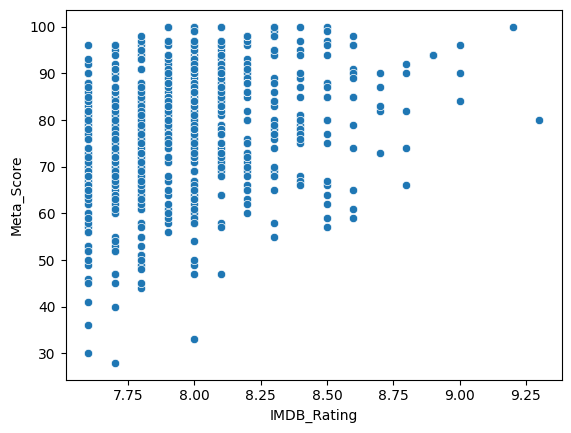

In [45]:
# Create a scatterplot of the two scores, "IMDB_Rating" and "Meta_score".
# In a sentence or two, describe what this pair of scores suggests about the movies.

# This scatterplot shows the relationship between IMDB rating and meta score. Generally speaking movies with higher imdb ratings should have higher meta scores this is shown in the graph.

sns.scatterplot(data=imdb, x='IMDB_Rating', y='Meta_score')

plt.xlabel('IMDB_Rating')
plt.ylabel('Meta_Score')
plt.show()

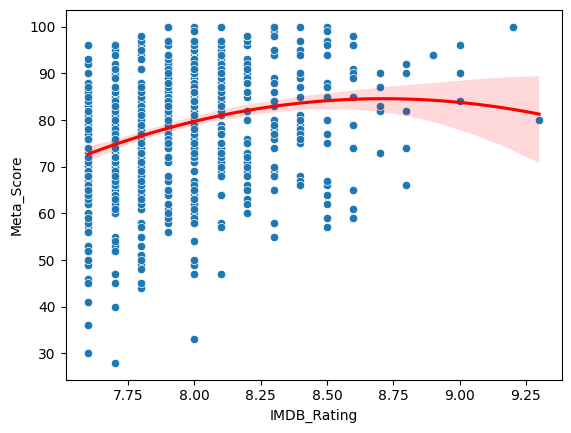

In [63]:
# Fit a trendline to show the relationship between the two scores.
# Hint: sns.regplot()
# Try a few values of the `order` argument (polynomial degree) for the trendline.

sns.scatterplot(data=imdb, x='IMDB_Rating', y='Meta_score')
sns.regplot(data=imdb, x='IMDB_Rating', y='Meta_score', order=2, scatter=False, color='Red')

plt.xlabel('IMDB_Rating')
plt.ylabel('Meta_Score')
plt.show()


In [77]:
# Do any data points in the scatterplot surprise you?
# Try to identify a few such movies.
imdb[(imdb['IMDB_Rating'] == 9.3) | ((imdb['IMDB_Rating'] == 8) & (imdb['Meta_score'] == 33))]



,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross,Runtime_min,Age_Years,Decade
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,28341469.0,142,32,1990
356,https://m.media-amazon.com/images/M/MV5BYmI1OD...,Tropa de Elite,2007,R,115 min,"Action, Crime, Drama",8.0,"In 1997 Rio de Janeiro, Captain Nascimento has...",33.0,José Padilha,Wagner Moura,André Ramiro,Caio Junqueira,Milhem Cortaz,98097,8060.0,115,19,2000


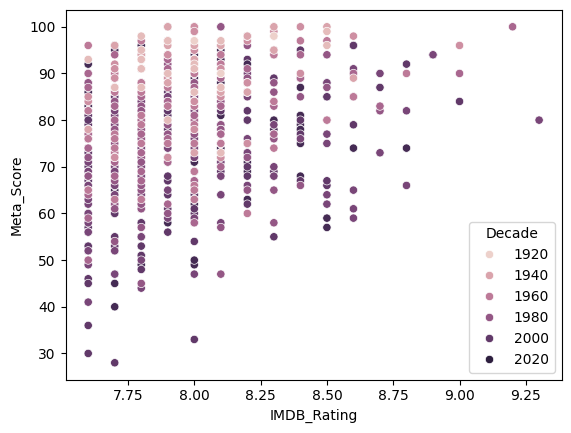

In [130]:
# In the scatterplot, use color to distinguish movies from different decades.

sns.scatterplot(data=imdb, x='IMDB_Rating', y='Meta_score', hue='Decade',)


plt.xlabel('IMDB_Rating')
plt.ylabel('Meta_Score')
plt.show()

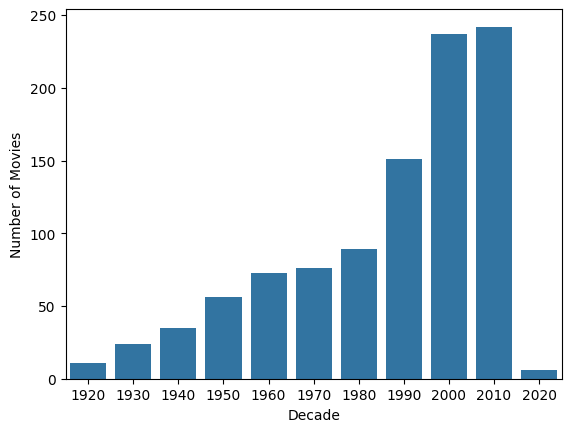

In [92]:
# Create a chart that shows how many movies fall into each decade.
sns.countplot(data=imdb, x='Decade')

plt.xlabel('Decade')
plt.ylabel('Number of Movies')
plt.show()

<Axes: ylabel='count'>

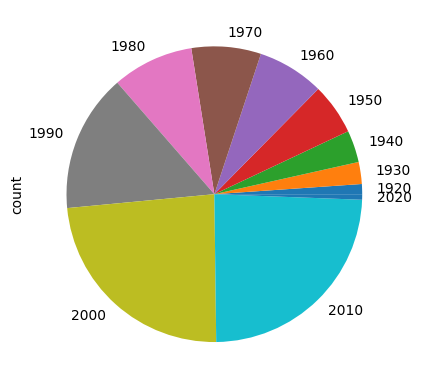

In [116]:
# Create a chart that shows the percentage of movies in each decade.
(imdb['Decade'].value_counts().sort_index() * 100).plot(kind='pie')

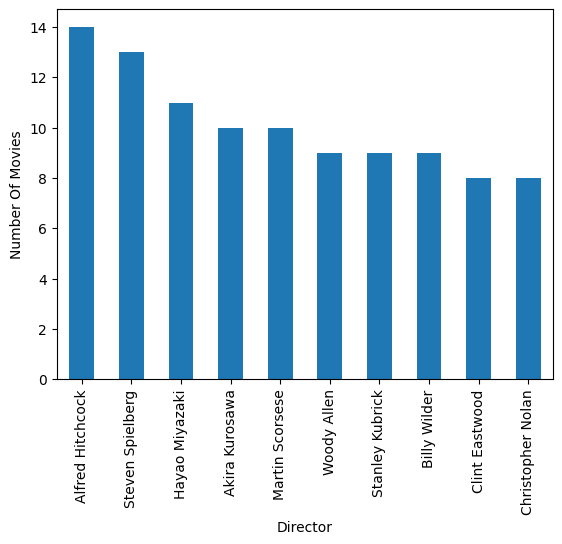

In [102]:
# Count movies by director.
# Show the top 10 directors by movie count in a bar chart.

imdb['Director'].value_counts().head(10).plot(kind='bar')

plt.xlabel('Director')
plt.ylabel('Number Of Movies')
plt.show()

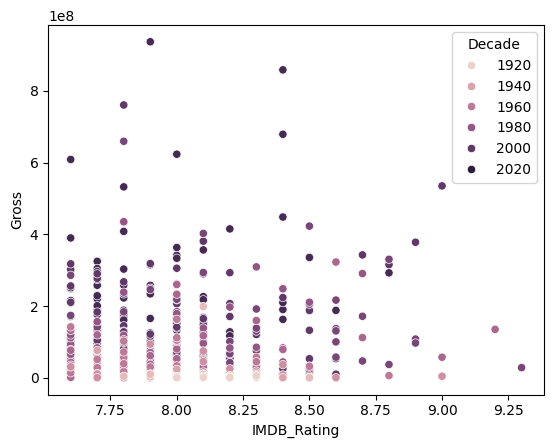

In [112]:
# Create a scatterplot of "IMDB_Rating" and "Gross".
# Use color to distinguish movies from different decades.
# Briefly interpret what the chart shows.

# This scatterplot shows the relationship between IMDB_Rating and gross revenue.
# The chart can specifically shows if higher rated movies earn more money or not.
# Showcasing decades in different colors also allows for figuring out patterns of gross revenue accross different decades.

sns.scatterplot(data=imdb, x='IMDB_Rating', y='Gross', hue='Decade',)

plt.xlabel('IMDB_Rating')
plt.ylabel('Gross')
plt.show()



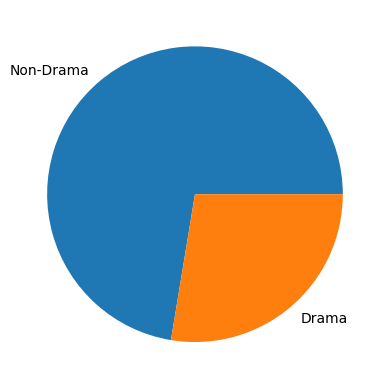

In [118]:
# Create a column named "Drama" that indicates whether a movie's Genre includes "Drama".
# Create a pie chart showing the share of drama vs. non-drama movies.

imdb['Drama'] = imdb['Genre'].str.contains('Drama')

imdb['Drama'].value_counts().plot(kind='pie', labels=['Non-Drama', 'Drama'])

plt.ylabel('')
plt.show()

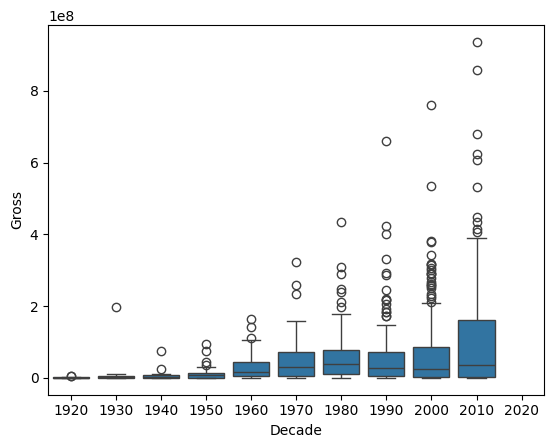

In [123]:
# Create a plot comparing Gross across decades.

sns.boxplot(data=imdb, x='Decade', y='Gross')

plt.xlabel('Decade')
plt.ylabel('Gross')
plt.show()

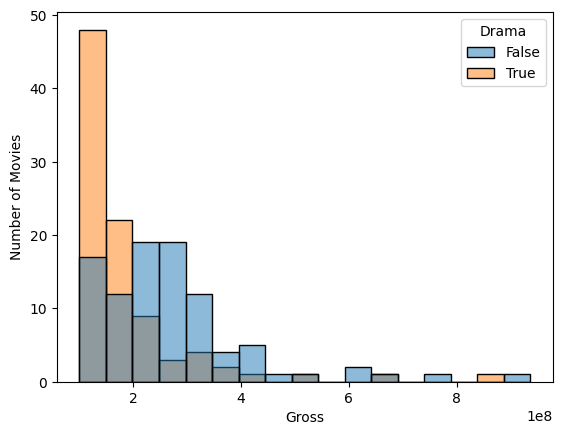

In [125]:
# For movies with Gross over $100 million:
# Create a histogram of Gross for drama vs. non-drama movies.

sns.histplot(data=imdb[imdb['Gross'] > 100000000], x='Gross', hue='Drama')

plt.xlabel('Gross')
plt.ylabel('Number of Movies')
plt.show()

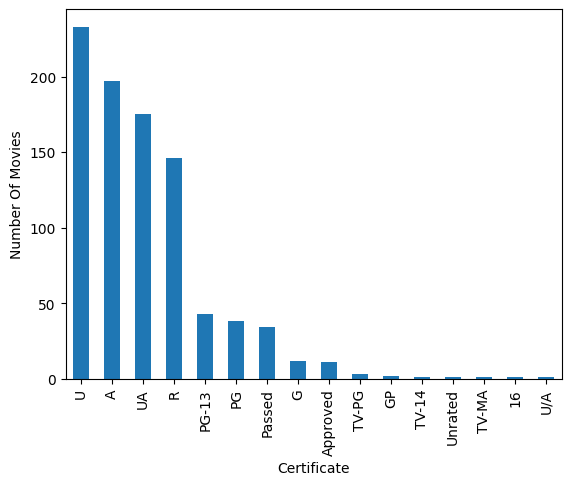

In [129]:
# Come up with two more questions about this dataset. Create one chart or figure for each.
# Question 1: Which certificates is the most common

imdb['Certificate'].value_counts().plot(kind='bar')

plt.xlabel('Certificate')
plt.ylabel('Number Of Movies')
plt.show()


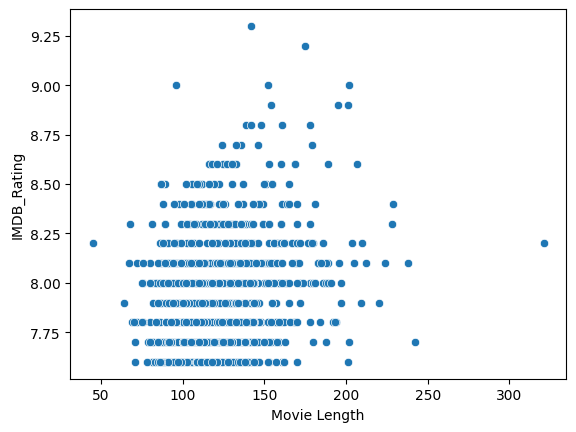

In [127]:
# Question 2: Do longer movies have a higher imdb rating

sns.scatterplot(data=imdb, x='Runtime_min', y='IMDB_Rating')

plt.xlabel('Movie Length')
plt.ylabel('IMDB_Rating')
plt.show()